# VAERS regression walkthrough
All-available-age sensitivity analysis. Place the original CSV beside this notebook and run all cells. Dependencies: numpy, scipy, pandas, matplotlib. The recorded-age primary analysis requires the archived age marker matched and checked by VAERS_ID and ORDER.

## Read the extract and check report keys


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from scipy import sparse
from scipy.optimize import linprog
from scipy.special import expit
from scipy.stats import chi2
import matplotlib.pyplot as plt


# Find the main GitHub project folder
ROOT = next(
    (
        folder
        for folder in [Path.cwd(), *Path.cwd().parents]
        if (folder / ".git").exists()
    ),
    None,
)

if ROOT is None:
    raise RuntimeError("Open the notebook inside the project.")

# Load the shared dataset
source = ROOT / "data" / "2022_COVID_VAERS_clean.csv"

if not source.is_file():
    raise FileNotFoundError(f"Dataset not found: {source}")

print("Dataset found:", source.is_file())
print("Dataset path:", source)

cols = ['VAERS_ID','ORDER','AGE_YRS','SEX','COVID_MANUFACTURERS','DIED_STATUS','HOSPITAL_STATUS']
raw = pd.read_csv(source, usecols=cols)
assert raw[['VAERS_ID','ORDER']].notna().all().all() and not raw.duplicated(['VAERS_ID','ORDER']).any()
for col in ['HOSPITAL_STATUS','DIED_STATUS']:
    assert set(raw[col].unique()) == {'Yes','Unknown'}
raw['flag'] = raw[['HOSPITAL_STATUS','DIED_STATUS']].eq('Yes').any(axis=1).astype(int)
def brand(value):
    values = set(json.loads(value))
    if len(values) == 1:
        return values.pop()
    return 'Mixed'
raw['brand'] = raw.COVID_MANUFACTURERS.map(brand)
brands = ['PFIZER\\BIONTECH','MODERNA','JANSSEN','NOVAVAX']
def select(last=False, mixed=False):
    ids = raw.sort_values('ORDER').drop_duplicates('VAERS_ID',keep='last' if last else 'first')
    known = ids[ids.SEX.isin(['M','F'])]
    d = known[known.brand.isin(brands + (['Mixed'] if mixed else []))].copy()
    print('source, IDs, known sex, eligible, flags:',len(raw),len(ids),len(known),len(d),d.flag.sum())
    return d
d = select()
print(pd.crosstab(d.brand,d.flag))


Dataset found: True
Dataset path: c:\Users\USER\OneDrive - NSBM\Documents\Stat\COVID-19_stat\data\2022_COVID_VAERS_clean.csv
source, IDs, known sex, eligible, flags: 215265 212164 200539 195953 30152
flag                 0      1
brand                        
JANSSEN           5383   2331
MODERNA          70606  12718
NOVAVAX            183     13
PFIZER\BIONTECH  89629  15090


## Build predictors and estimate mean age with HC3 uncertainty


In [2]:
def design(data, groups):
    return np.column_stack([np.ones(len(data)), data.SEX.eq('M')] + [data.brand.eq(b) for b in groups[1:]])
def mean_age(data, groups):
    x = np.column_stack([design(data,groups), data.flag])
    y = data.AGE_YRS.to_numpy()
    inv = np.linalg.inv(x.T @ x)
    b = inv @ (x.T @ y)
    residual = y - x @ b
    leverage = ((x @ inv)*x).sum(axis=1)
    weighted = x * (residual/(1-leverage))[:,None]
    se = np.sqrt((inv @ (weighted.T @ weighted) @ inv).diagonal())
    return b,se,x @ b,residual,leverage


## Fit median regression by minimizing weighted absolute deviations


In [3]:
def median_age(data,groups,reps):
    cells = data.groupby(['SEX','brand','flag','AGE_YRS']).size().reset_index(name='n')
    x = np.column_stack([design(cells,groups),cells.flag])
    y = cells.AGE_YRS.to_numpy()
    # Dual linear program has only one equality per coefficient.
    def solve(n):
        result = linprog(-y,A_eq=x.T,b_eq=np.zeros(x.shape[1]),bounds=np.column_stack([-n/2,n/2]),method='highs')
        assert result.success
        return -result.eqlin.marginals
    n = cells.n.to_numpy()
    b = solve(n)
    rng = np.random.default_rng(42)
    draws = [solve(rng.multinomial(n.sum(),n/n.sum())) for i in range(reps)]
    return b,np.percentile(draws,[2.5,97.5],axis=0)


## Fit logistic models using binomial likelihood and check age curvature


In [4]:
def logistic(data, groups, quadratic=True):
    cells = data.groupby(['SEX','brand','AGE_YRS']).flag.agg(['size','sum']).reset_index()
    a = (cells.AGE_YRS.to_numpy()-50)/10
    x = np.column_stack([design(cells,groups),a])
    if quadratic:
        x = np.column_stack([x,a*a])
    n,k = cells['size'].to_numpy(),cells['sum'].to_numpy()
    b = np.zeros(x.shape[1])
    for _ in range(80):
        eta = x @ b
        p = expit(eta)
        h = x.T @ ((n*p*(1-p))[:,None]*x)
        step = np.linalg.solve(h,x.T @ (k-n*p))
        if max(abs(step)) < 1e-9:
            break
        b += step
    else:
        raise RuntimeError('Logistic fit did not converge')
    return b,np.linalg.inv(h),sum(k*eta-n*np.logaddexp(0,eta))


## Estimate results and repeat key contrasts in alternative cohorts


In [5]:
groups = brands
labels = ['Intercept','Male vs female']+[b+' vs Pfizer' for b in groups[1:]]
b,se,fitted,res,h = mean_age(d,groups)
m,ci = median_age(d,groups,200)
l,cov,ll = logistic(d,groups)
linear_ll = logistic(d,groups,False)[2]
print('Quadratic likelihood ratio statistic, p:',2*(ll-linear_ll),chi2.sf(2*(ll-linear_ll),1))
rows = []
def record(model,names,est,lo,hi):
    rows.extend(zip([model]*len(names),names,est,lo,hi))
record('Mean age, years',labels+['Flag'],b,b-1.96*se,b+1.96*se)
record('Median age, years',labels+['Flag'],m,*ci)
ls = np.sqrt(cov.diagonal())
record('Logistic, exp(coefficient)',labels+['Centered age in decades','Centered decades squared'],np.exp(l),np.exp(l-1.96*ls),np.exp(l+1.96*ls))
table = pd.DataFrame(rows,columns=['Model','Term','Estimate','Lower95','Upper95'])
table.to_csv(ROOT / 'analysis' / 'tharusha' / 'outputs' / 'coefficients.csv', index=False)
print(table.round(3).to_string(index=False))
checks = []
for name,data,g in [('All available ages',d,brands),('Adults',d[d.AGE_YRS>=18],brands),('Highest ORDER',select(last=True),brands),('Include mixed lists',select(mixed=True),brands+['Mixed'])]:
    checks.append([name,len(data),mean_age(data,g)[0][-1], median_age(data,g,2)[0][-1],np.exp(logistic(data,g)[0][1])])
checks = pd.DataFrame(checks,columns=['Cohort','Reports','Mean age contrast','Median age contrast','Male odds ratio'])
print(checks.round(3).to_string(index=False))
checks.to_csv(ROOT / 'analysis' / 'tharusha' / 'outputs' / 'sensitivity.csv', index=False)


Quadratic likelihood ratio statistic, p: 1450.8239414426498 0.0
                     Model                     Term  Estimate  Lower95  Upper95
           Mean age, years                Intercept    45.930   45.779   46.080
           Mean age, years           Male vs female    -1.341   -1.533   -1.148
           Mean age, years        MODERNA vs Pfizer     7.077    6.890    7.263
           Mean age, years        JANSSEN vs Pfizer     1.665    1.283    2.047
           Mean age, years        NOVAVAX vs Pfizer     1.655   -0.924    4.234
           Mean age, years                     Flag    17.400   17.162   17.637
         Median age, years                Intercept    51.000   51.000   52.000
         Median age, years           Male vs female     0.000    0.000    0.000
         Median age, years        MODERNA vs Pfizer     4.000    3.000    4.000
         Median age, years        JANSSEN vs Pfizer    -1.000   -2.000    0.000
         Median age, years        NOVAVAX vs Pfizer    -

## Plot adjusted odds as probabilities and inspect mean-model residuals


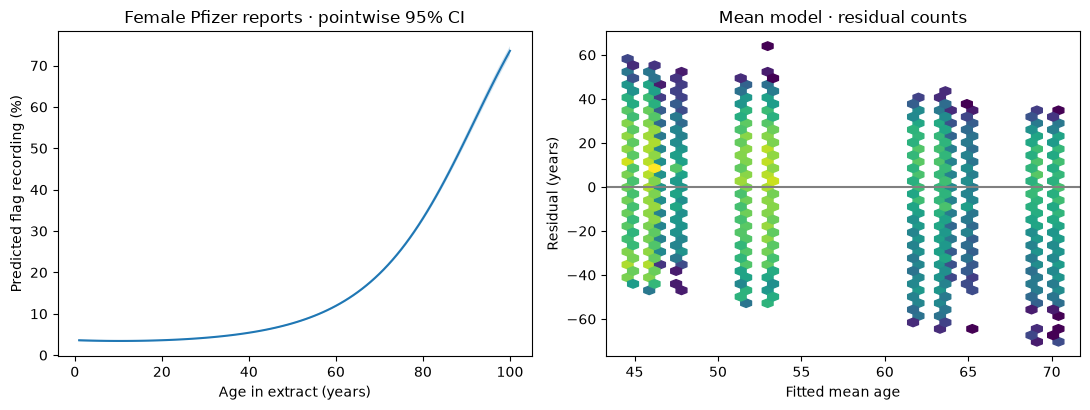

Maximum leverage and Cook distance: 0.005142961311406433 0.004299796074788812


In [6]:
ages = np.arange(1,101)
a = (ages-50)/10
grid = np.column_stack([np.ones(len(a)),np.zeros((len(a),len(labels)-1)),a,a*a])
eta = grid @ l
margin = 1.96*np.sqrt(((grid @ cov)*grid).sum(axis=1))
fig,ax = plt.subplots(1,2,figsize=(11,4.2))
ax[0].plot(ages,100*expit(eta))
ax[0].fill_between(ages,100*expit(eta-margin),100*expit(eta+margin),alpha=.2)
ax[0].set(xlabel='Age in extract (years)',ylabel='Predicted flag recording (%)',title='Female Pfizer reports · pointwise 95% CI')
ax[1].hexbin(fitted,res,gridsize=40,mincnt=1,bins='log')
ax[1].axhline(0,color='grey')
ax[1].set(xlabel='Fitted mean age',ylabel='Residual (years)',title='Mean model · residual counts')
fig.tight_layout()
fig.savefig(ROOT / 'analysis' / 'tharusha' / 'figures' / 'diagnostics.png', dpi=170)
plt.show()
cook = res**2 / (len(b)*(res@res/(len(d)-len(b)))) * h/(1-h)**2
print('Maximum leverage and Cook distance:',h.max(),cook.max())
